# Data Science Tool Mastery Portfolio
**Dataset:** Palmer Penguins (344 penguins, 3 species, measured at Palmer Station, Antarctica; from the `seaborn-data` repository).
**Question that ties the tools together:** can we tell the three penguin species apart from their body measurements, and what does the data say about how the measurements relate?

Each section demonstrates one industry-standard tool: **NumPy, pandas, SQL (SQLite), Matplotlib/seaborn, SciPy, scikit-learn**.

In [1]:
import sqlite3
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
import sklearn
sns.set_theme(style='whitegrid')
PAL = {'Adelie':'#C2410C','Chinstrap':'#6B7280','Gentoo':'#1D4E89'}
for m in (np, pd, sns, sklearn): print(f'{m.__name__:<10}{m.__version__}')
raw = pd.read_csv('penguins.csv'); print(raw.shape)

numpy     2.5.3
pandas    3.0.5
seaborn   0.13.2
sklearn   1.9.1
(344, 7)


## 1. NumPy: arrays, vectorisation, broadcasting

In [2]:
mass = raw['body_mass_g'].dropna().to_numpy()
print('mean %.1f | median %.1f | std %.1f' % (mass.mean(), np.median(mass), mass.std(ddof=1)))
print('percentiles 5/50/95:', np.percentile(mass, [5,50,95]))
# vectorised z-score, no loops
z = (mass - mass.mean()) / mass.std(ddof=1)
print('Penguins more than 2 SD from the mean:', int((np.abs(z) > 2).sum()))
# broadcasting: standardise every numeric column at once
num = raw[['bill_length_mm','bill_depth_mm','flipper_length_mm','body_mass_g']].dropna().to_numpy()
std = (num - num.mean(axis=0)) / num.std(axis=0)
print('Column means after standardising:', std.mean(axis=0).round(10))
# speed: loop vs vectorised
import timeit
x = np.random.default_rng(0).normal(size=1_000_000); xl = x.tolist()
def loop():
    s = 0.0
    for v in xl: s += v*v
    return s
t_loop = min(timeit.repeat(loop, number=1, repeat=5))
t_vec = min(timeit.repeat(lambda: np.dot(x, x), number=20, repeat=5)) / 20
print(f'Sum of squares, 1M values: Python loop {t_loop*1000:.1f} ms vs NumPy {t_vec*1000:.2f} ms ({t_loop/t_vec:.0f}x faster)')

mean 4201.8 | median 4050.0 | std 802.0
percentiles 5/50/95: [3150. 4050. 5650.]
Penguins more than 2 SD from the mean: 9
Column means after standardising: [ 0. -0. -0.  0.]


Sum of squares, 1M values: Python loop 22.9 ms vs NumPy 0.41 ms (56x faster)


## 2. pandas: inspect, clean, reshape, aggregate

In [3]:
print(raw.isna().sum()[raw.isna().sum()>0].to_dict(), '| duplicates:', raw.duplicated().sum())
print(raw[raw.isna().sum(axis=1) >= 4])

{'bill_length_mm': 2, 'bill_depth_mm': 2, 'flipper_length_mm': 2, 'body_mass_g': 2, 'sex': 11} | duplicates: 0
    species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
3    Adelie  Torgersen             NaN            NaN                NaN   
339  Gentoo     Biscoe             NaN            NaN                NaN   

     body_mass_g  sex  
3            NaN  NaN  
339          NaN  NaN  


In [4]:
df = raw.copy()
df['sex'] = df['sex'].str.title()
df = df.dropna(subset=['bill_length_mm'])          # 2 rows with no measurements at all
df['sex'] = df['sex'].fillna('Unknown')             # keep rows, label unknown sex
for c in ['species','island','sex']: df[c] = df[c].astype('category')
df['bill_ratio'] = df['bill_length_mm'] / df['bill_depth_mm']
df['mass_kg'] = df['body_mass_g'] / 1000
print(df.shape, '| missing numeric values:', int(df.select_dtypes('number').isna().sum().sum()))

(342, 9) | missing numeric values: 0


In [5]:
summary = (df.groupby('species', observed=True)
             .agg(n=('species','size'), mass_kg=('mass_kg','mean'), flipper=('flipper_length_mm','mean'),
                  bill_len=('bill_length_mm','mean'), bill_depth=('bill_depth_mm','mean'))
             .round(2))
print(summary); print()
print(pd.crosstab(df.island, df.species)); print()
print(df.pivot_table(index='species', columns='sex', values='mass_kg', aggfunc='mean', observed=True).round(2))

             n  mass_kg  flipper  bill_len  bill_depth
species                                               
Adelie     151     3.70   189.95     38.79       18.35
Chinstrap   68     3.73   195.82     48.83       18.42
Gentoo     123     5.08   217.19     47.50       14.98

species    Adelie  Chinstrap  Gentoo
island                              
Biscoe         44          0     123
Dream          56         68       0
Torgersen      51          0       0

sex        Female  Male  Unknown
species                         
Adelie       3.37  4.04     3.54
Chinstrap    3.53  3.94      NaN
Gentoo       4.68  5.48     4.59


## 3. SQL (SQLite via Python): the same questions in SQL

In [6]:
con = sqlite3.connect(':memory:')
df.assign(species=df.species.astype(str), island=df.island.astype(str), sex=df.sex.astype(str)).to_sql('penguins', con, index=False)
q1 = '''
SELECT species, COUNT(*) AS n, ROUND(AVG(body_mass_g)/1000.0, 2) AS avg_mass_kg
FROM penguins GROUP BY species ORDER BY avg_mass_kg DESC'''
print(pd.read_sql(q1, con)); print()
q2 = '''
SELECT island, species, COUNT(*) AS n,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (PARTITION BY island), 1) AS pct_of_island
FROM penguins GROUP BY island, species ORDER BY island, n DESC'''
print(pd.read_sql(q2, con)); print()
q3 = '''
WITH sp AS (SELECT species, AVG(body_mass_g) AS m FROM penguins GROUP BY species)
SELECT p.species, p.island, p.sex, p.body_mass_g
FROM penguins p JOIN sp USING (species)
WHERE p.body_mass_g > sp.m + 500 ORDER BY p.body_mass_g DESC LIMIT 5'''
print(pd.read_sql(q3, con))

     species    n  avg_mass_kg
0     Gentoo  123         5.08
1  Chinstrap   68         3.73
2     Adelie  151         3.70

      island    species    n  pct_of_island
0     Biscoe     Gentoo  123           73.7
1     Biscoe     Adelie   44           26.3
2      Dream  Chinstrap   68           54.8
3      Dream     Adelie   56           45.2
4  Torgersen     Adelie   51          100.0

  species  island   sex  body_mass_g
0  Gentoo  Biscoe  Male       6300.0
1  Gentoo  Biscoe  Male       6050.0
2  Gentoo  Biscoe  Male       6000.0
3  Gentoo  Biscoe  Male       6000.0
4  Gentoo  Biscoe  Male       5950.0


## 4. Matplotlib and seaborn: communicating the data

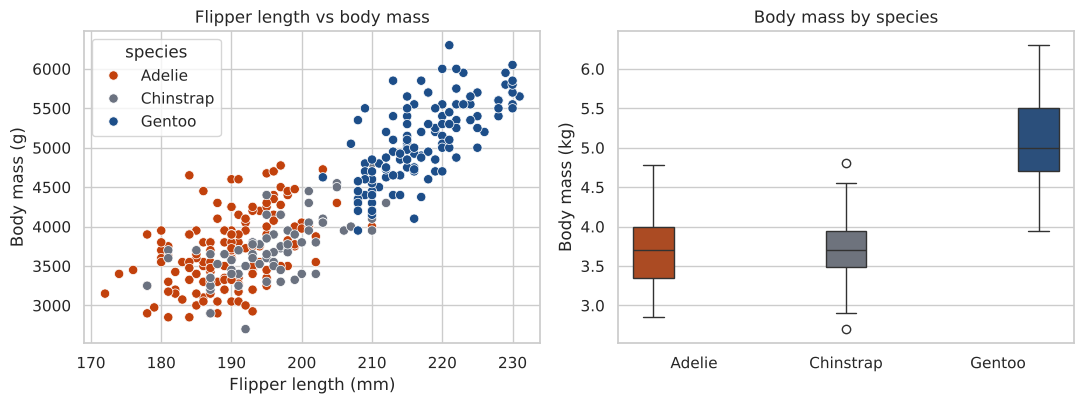

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11,4.2))
sns.scatterplot(data=df, x='flipper_length_mm', y='body_mass_g', hue='species', palette=PAL, ax=ax[0], s=45)
ax[0].set(title='Flipper length vs body mass', xlabel='Flipper length (mm)', ylabel='Body mass (g)')
sns.boxplot(data=df, x='species', y='mass_kg', hue='species', palette=PAL, ax=ax[1], legend=False)
ax[1].set(title='Body mass by species', xlabel='', ylabel='Body mass (kg)')
plt.tight_layout(); plt.savefig('fig1_scatter_box.png', dpi=150)

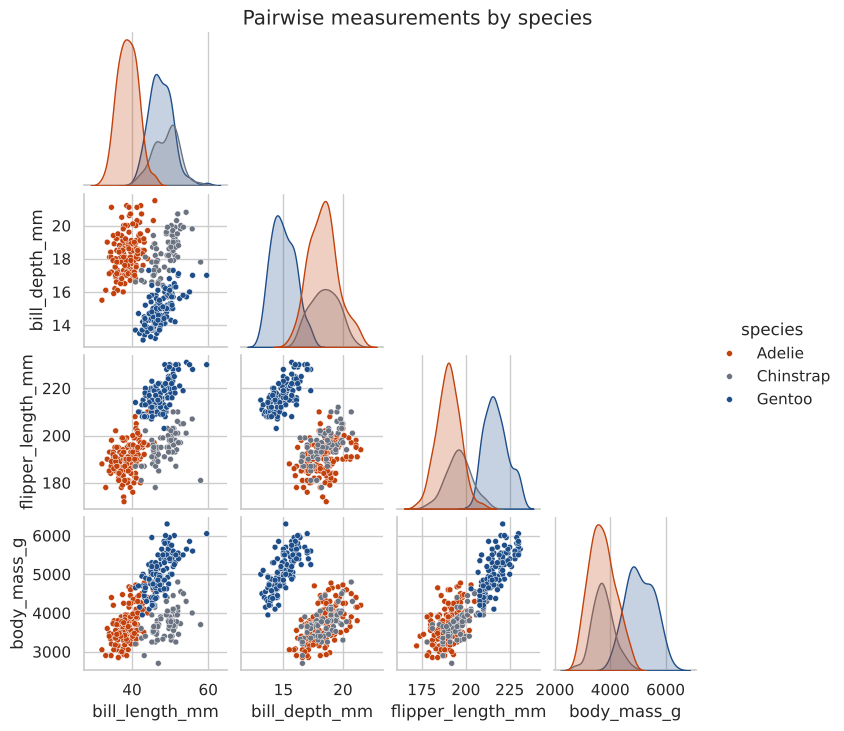

In [8]:
g = sns.pairplot(df, vars=['bill_length_mm','bill_depth_mm','flipper_length_mm','body_mass_g'],
                 hue='species', palette=PAL, corner=True, height=1.8, plot_kws={'s':18})
g.figure.suptitle('Pairwise measurements by species', y=1.01)
g.savefig('fig2_pairplot.png', dpi=130)

Pooled correlation: -0.24
species
Adelie       0.39
Chinstrap    0.65
Gentoo       0.64
dtype: float64


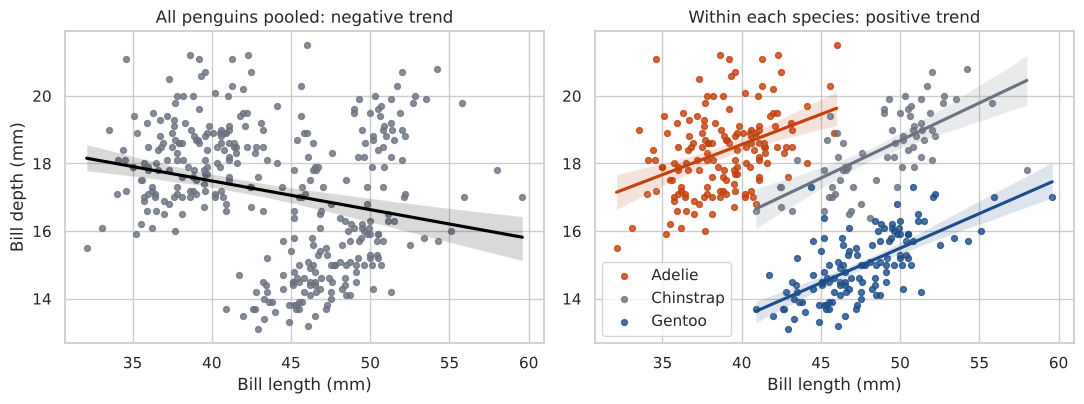

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11,4.2))
sns.regplot(data=df, x='bill_length_mm', y='bill_depth_mm', scatter_kws={'s':18,'color':'#6B7280'}, line_kws={'color':'black'}, ax=ax[0])
ax[0].set(title='All penguins pooled: negative trend', xlabel='Bill length (mm)', ylabel='Bill depth (mm)')
for sp, col in PAL.items():
    s = df[df.species==sp]
    sns.regplot(data=s, x='bill_length_mm', y='bill_depth_mm', scatter_kws={'s':18,'color':col}, line_kws={'color':col}, ax=ax[1], label=sp)
ax[1].set(title='Within each species: positive trend', xlabel='Bill length (mm)', ylabel=''); ax[1].legend()
plt.tight_layout(); plt.savefig('fig3_simpson.png', dpi=150)
r_all = df['bill_length_mm'].corr(df['bill_depth_mm'])
print('Pooled correlation: %.2f' % r_all)
print(df.groupby('species', observed=True).apply(lambda s: s['bill_length_mm'].corr(s['bill_depth_mm']), include_groups=False).round(2))

## 5. SciPy: statistical testing

In [10]:
groups = [g['body_mass_g'].to_numpy() for _, g in df.groupby('species', observed=True)]
# assumption checks
print('Shapiro-Wilk p per species:', [round(stats.shapiro(g).pvalue, 3) for g in groups])
print('Levene (equal variance) p:', round(stats.levene(*groups).pvalue, 3))
f, p = stats.f_oneway(*groups); print(f'One-way ANOVA on body mass: F = {f:.1f}, p = {p:.2e}')
print('Kruskal-Wallis (non-parametric check) p = %.2e' % stats.kruskal(*groups).pvalue)
print('Group order in Tukey table: 0 = Adelie, 1 = Chinstrap, 2 = Gentoo')
print(stats.tukey_hsd(*groups))

Shapiro-Wilk p per species: [np.float64(0.032), np.float64(0.561), np.float64(0.234)]
Levene (equal variance) p: 0.006
One-way ANOVA on body mass: F = 343.6, p = 2.89e-82
Kruskal-Wallis (non-parametric check) p = 5.61e-48
Group order in Tukey table: 0 = Adelie, 1 = Chinstrap, 2 = Gentoo


Pairwise Group Comparisons (95.0% Confidence Interval)
Comparison  Statistic  p-value  Lower CI  Upper CI
 (0 - 1)    -32.426     0.881  -191.352   126.500
 (0 - 2)  -1375.354     0.000 -1507.529 -1243.179
 (1 - 0)     32.426     0.881  -126.500   191.352
 (1 - 2)  -1342.928     0.000 -1507.375 -1178.481
 (2 - 0)   1375.354     0.000  1243.179  1507.529
 (2 - 1)   1342.928     0.000  1178.481  1507.375



In [11]:
m = df[df.sex=='Male']['body_mass_g']; fm = df[df.sex=='Female']['body_mass_g']
t, p = stats.ttest_ind(m, fm, equal_var=False)
d = (m.mean()-fm.mean()) / np.sqrt((m.var(ddof=1)+fm.var(ddof=1))/2)
print(f'Male {m.mean():.0f} g vs female {fm.mean():.0f} g: t = {t:.1f}, p = {p:.2e}, Cohen d = {d:.2f}')
ct = pd.crosstab(df.island, df.species); chi2, p, dof, _ = stats.chi2_contingency(ct)
print(f'Island vs species: chi2 = {chi2:.1f}, dof = {dof}, p = {p:.2e}')

Male 4546 g vs female 3862 g: t = 8.6, p = 4.79e-16, Cohen d = 0.94
Island vs species: chi2 = 296.5, dof = 4, p = 6.20e-63


## 6. scikit-learn: a leak-free ML pipeline

In [12]:
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

num_cols = ['bill_length_mm','bill_depth_mm','flipper_length_mm','body_mass_g']
cat_cols = ['sex']
X = df[num_cols + cat_cols].copy(); X['sex'] = X['sex'].astype(str); y = df['species'].astype(str)
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
prep = ColumnTransformer([
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)])
models = {'Baseline (most frequent)': DummyClassifier(strategy='most_frequent'),
          'Logistic regression': LogisticRegression(max_iter=1000),
          'Random forest': RandomForestClassifier(n_estimators=300, random_state=0)}
cv = StratifiedKFold(5, shuffle=True, random_state=0)
pipes = {n: Pipeline([('prep', prep), ('model', m)]) for n, m in models.items()}
for n, pipe in pipes.items():
    s = cross_val_score(pipe, Xtr, ytr, cv=cv)
    print(f'{n:<26} CV accuracy {s.mean():.3f} (+/- {s.std():.3f})')

Baseline (most frequent)   CV accuracy 0.441 (+/- 0.009)
Logistic regression        CV accuracy 0.992 (+/- 0.010)


Random forest              CV accuracy 0.988 (+/- 0.024)


              precision    recall  f1-score   support

      Adelie      1.000     1.000     1.000        38
   Chinstrap      1.000     1.000     1.000        17
      Gentoo      1.000     1.000     1.000        31

    accuracy                          1.000        86
   macro avg      1.000     1.000     1.000        86
weighted avg      1.000     1.000     1.000        86



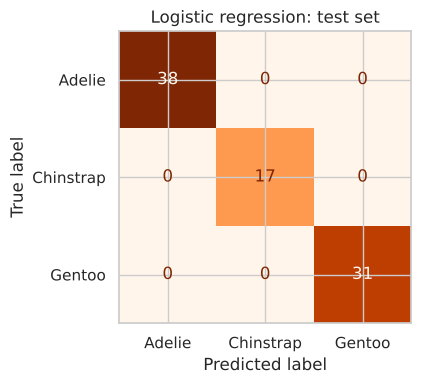

In [13]:
best = pipes['Logistic regression'].fit(Xtr, ytr)
pred = best.predict(Xte)
print(classification_report(yte, pred, digits=3))
fig, ax = plt.subplots(figsize=(4.8,4))
ConfusionMatrixDisplay.from_predictions(yte, pred, cmap='Oranges', colorbar=False, ax=ax)
ax.set_title('Logistic regression: test set'); plt.tight_layout(); plt.savefig('fig4_confusion.png', dpi=150)

Random forest test accuracy: 1.0
bill_length_mm       0.378
flipper_length_mm    0.248
bill_depth_mm        0.211
body_mass_g          0.144
sex_Male             0.010
sex_Female           0.007
sex_Unknown          0.001
dtype: float64


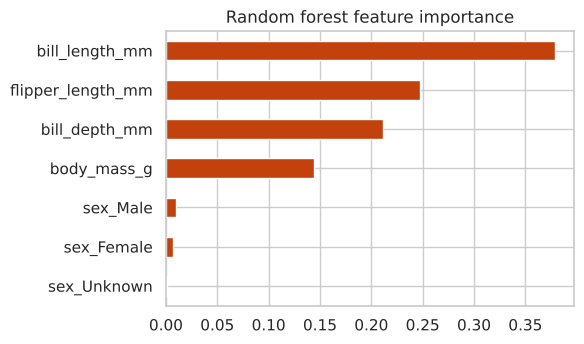

In [14]:
rf = pipes['Random forest'].fit(Xtr, ytr)
names = rf.named_steps['prep'].get_feature_names_out()
imp = pd.Series(rf.named_steps['model'].feature_importances_, index=[n.split('__')[1] for n in names]).sort_values()
print('Random forest test accuracy:', round(rf.score(Xte, yte), 3))
fig, ax = plt.subplots(figsize=(6,3.6)); imp.plot.barh(color='#C2410C', ax=ax)
ax.set(title='Random forest feature importance'); plt.tight_layout(); plt.savefig('fig5_importance.png', dpi=150)
print(imp.round(3).sort_values(ascending=False))